In [39]:
import numpy as np
import matplotlib.pyplot as plt

In [40]:
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick',labelsize=10)

In [41]:
def sigmoid(t):
    return 1/(1+ np.exp(-t))

In [42]:
t = np.linspace(-10,10,50)
sig_t =sigmoid(t)

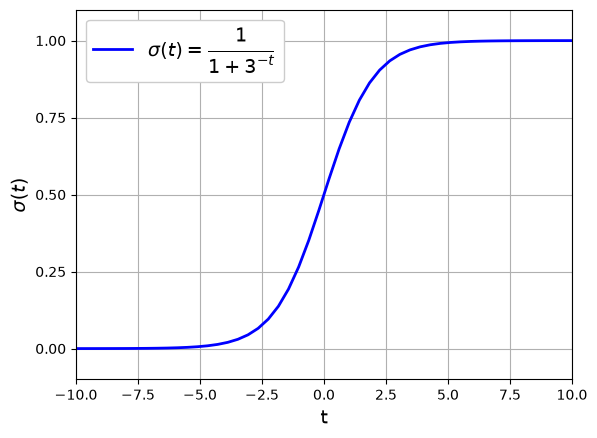

In [43]:
plt.plot(t,sig_t, 'b-',linewidth=2, label=r'$\sigma(t) = \dfrac{1}{1+3^{-t}}$' )
plt.xlabel('t')
plt.ylabel(r'$\sigma(t)$')
plt.legend(loc='upper left' ,framealpha=1.0)
plt.axis([-10,10,-0.1,1.1])
plt.gca().set_yticks([0,0.25,0.5,0.75,1])
plt.grid(True)
plt.show()


In [44]:
X = np.array([0.052, 0.081, 0.096, 0.158, 0.242, 0.253, 0.396, 0.427, 0.459, 0.572])
y = np.array([0, 0, 0, 0, 1, 0, 1, 1, 1, 1])

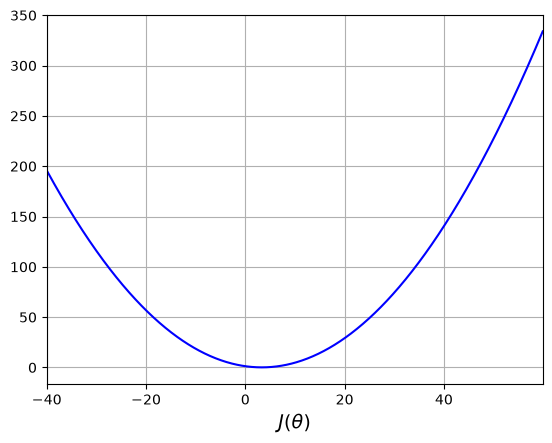

In [45]:
m = X.size
theta1 = np.arange(-40, 60, 0.1)
h = np.array([-0.5 + theta*X for theta in theta1])
J = (1/m)*((h-y)**2).sum(axis=1)

plt.xlabel(r'$\theta$')
plt.xlabel(r'$J(\theta)$')
plt.plot(theta1, J, 'b-')
plt.xlim(theta1.min(), theta1.max())
plt.grid(True)
plt.show()

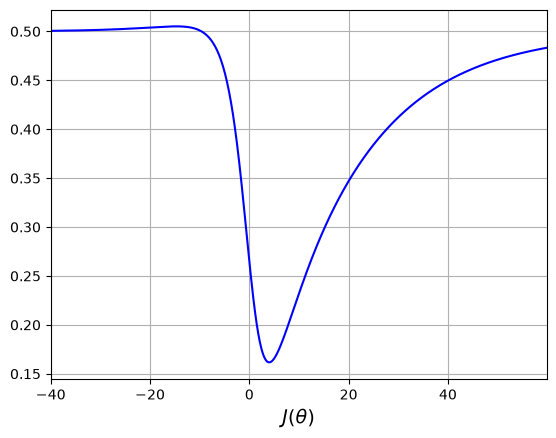

In [46]:
m = X.size
theta1 = np.arange(-40, 60, 0.1)
h = np.array([-0.5 + theta*X for theta in theta1])
h = sigmoid(h)
J = (1/m)*((h-y)**2).sum(axis=1)

plt.xlabel(r'$\theta$')
plt.xlabel(r'$J(\theta)$')
plt.plot(theta1, J, 'b-')
plt.xlim(theta1.min(), theta1.max())
plt.grid(True)
plt.show()

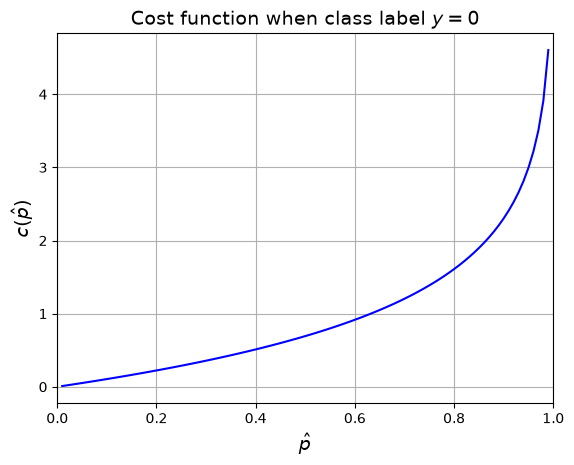

In [47]:
p = np.arange(0.01, 1, 0.01)
c = -np.log(1-p)

plt.plot(p, c, 'b-')

plt.xlabel(r'$\hat{p}$')
plt.ylabel(r'$c(\hat{p})$')
plt.title(r'Cost function when class label $y=0$')
plt.xlim(0, 1)
plt.grid(True)
plt.show()

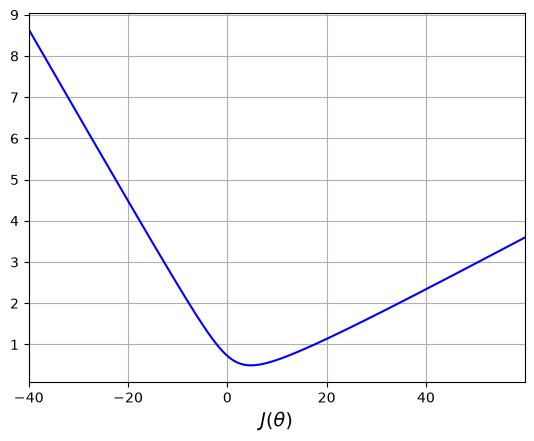

In [48]:
m = X.size
theta1 = np.arange(-40, 60, 0.1)
h = np.array([-0.5 + theta*X for theta in theta1])
h = sigmoid(h)
#J = (1/m)*((h-y)**2).sum(axis=1)
J = -(1/m)*(y*np.log(h) + (1-y)*np.log(1-h)).sum(axis=1)


plt.xlabel(r'$\theta$')
plt.xlabel(r'$J(\theta)$')
plt.plot(theta1, J, 'b-')
plt.xlim(theta1.min(), theta1.max())
plt.grid(True)
plt.show()

In [49]:
from sklearn import datasets
iris = datasets.load_iris()

In [50]:
print(iris.DESCR)

.. _iris_dataset:

Iris plants dataset
--------------------

**Data Set Characteristics:**

:Number of Instances: 150 (50 in each of three classes)
:Number of Attributes: 4 numeric, predictive attributes and the class
:Attribute Information:
    - sepal length in cm
    - sepal width in cm
    - petal length in cm
    - petal width in cm
    - class:
            - Iris-Setosa
            - Iris-Versicolour
            - Iris-Virginica

:Summary Statistics:

============== ==== ==== ======= ===== ====================
                Min  Max   Mean    SD   Class Correlation
============== ==== ==== ======= ===== ====================
sepal length:   4.3  7.9   5.84   0.83    0.7826
sepal width:    2.0  4.4   3.05   0.43   -0.4194
petal length:   1.0  6.9   3.76   1.76    0.9490  (high!)
petal width:    0.1  2.5   1.20   0.76    0.9565  (high!)
============== ==== ==== ======= ===== ====================

:Missing Attribute Values: None
:Class Distribution: 33.3% for each of 3 classes.
:Cr

In [51]:
iris.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [52]:
from sklearn.preprocessing import add_dummy_feature

In [53]:
#petal widht
X = iris.data[:,3:]
X_b = add_dummy_feature(X)

In [54]:
#detect iris virginica
y = (iris.target ==2).astype(int)[:,np.newaxis]


In [55]:
m = X.shape[0]
eta = 10
n_epochs = 10000

In [56]:
rng = np.random.default_rng(seed=42)

In [57]:
theta = rng.standard_normal((2, 1))
theta

array([[ 0.30471708],
       [-1.03998411]])

In [58]:
for i in range(n_epochs):
    gradients = 1/m * X_b.T @ (sigmoid(X_b@theta) - y)
    theta = theta - eta * gradients

theta

array([[-21.12564008],
       [ 12.94750723]])

Decision boundary = 1.6336336336336337


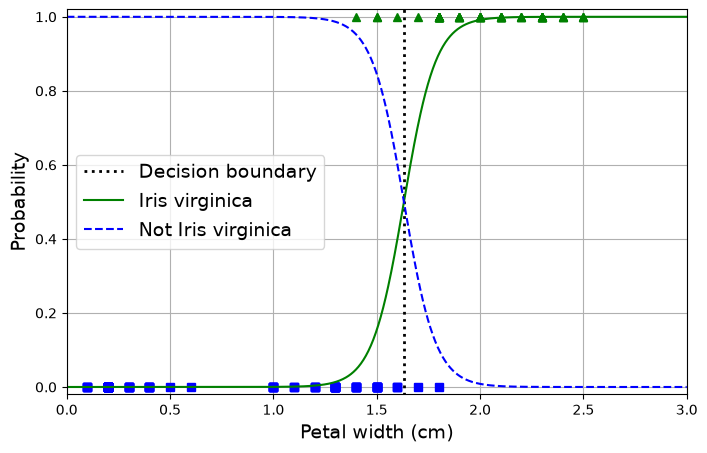

In [59]:
X_new = np.linspace(0, 3, 1000)[:, np.newaxis]
X_new_b = add_dummy_feature(X_new)
y_proba = sigmoid(X_new_b @ theta)

decision_boundary = X_new[y_proba >= 0.5][0]
print(f'Decision boundary = {decision_boundary}')

plt.figure(figsize=(8, 5))
plt.plot(X[y==0], y[y==0], 'bs')
plt.plot(X[y==1], y[y==1], 'g^')
plt.plot([decision_boundary, decision_boundary], [-1, 2], 'k:', linewidth=2, label='Decision boundary')

plt.plot(X_new, y_proba, 'g-', label='Iris virginica')
plt.plot(X_new, 1-y_proba, 'b--', label='Not Iris virginica')

plt.xlabel('Petal width (cm)')
plt.ylabel('Probability')
plt.legend(loc='center left')
plt.axis([0, 3, -0.02, 1.02])
plt.grid(True)
plt.show()

In [60]:
from sklearn.linear_model import LogisticRegression #Considera regularizacion, el cual es un metodo que ayuda a no caer en el overfitting

In [61]:
model = LogisticRegression(C=10**10)
model.fit(X, y.ravel())

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10000000000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good def

In [62]:
model.predict([[0.8], [1.5], [1.8]])

array([0, 0, 1])

In [63]:
model.predict_proba([[0.8], [1.5], [1.8]])

array([[9.99979055e-01, 2.09450351e-05],
       [8.46231615e-01, 1.53768385e-01],
       [1.01465710e-01, 8.98534290e-01]])

Decision boundary = 1.6336336336336337


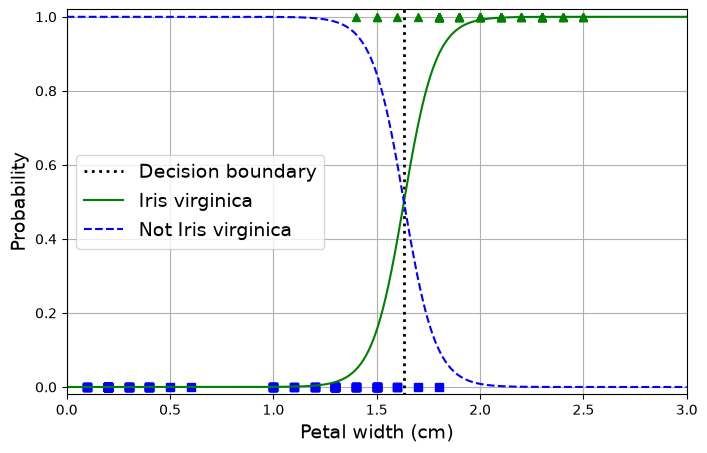

In [64]:
X_new = np.linspace(0, 3, 1000)[:, np.newaxis]
y_proba = model.predict_proba(X_new)[:, 1:]

decision_boundary = X_new[y_proba >= 0.5][0]
print(f'Decision boundary = {decision_boundary}')

plt.figure(figsize=(8, 5))
plt.plot(X[y==0], y[y==0], 'bs')
plt.plot(X[y==1], y[y==1], 'g^')
plt.plot([decision_boundary, decision_boundary], [-1, 2], 'k:', linewidth=2, label='Decision boundary')

plt.plot(X_new, y_proba, 'g-', label='Iris virginica')
plt.plot(X_new, 1-y_proba, 'b--', label='Not Iris virginica')

plt.xlabel('Petal width (cm)')
plt.ylabel('Probability')
plt.legend(loc='center left')
plt.axis([0, 3, -0.02, 1.02])
plt.grid(True)
plt.show()

In [68]:
# petal length width
X = iris.data[:, (2,3)]
y = (iris.target == 2).astype(int) #Investigar a que hacer referencia el iris.target

In [69]:
model = LogisticRegression(C=10**10)
model.fit(X, y)

,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",10000000000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good def

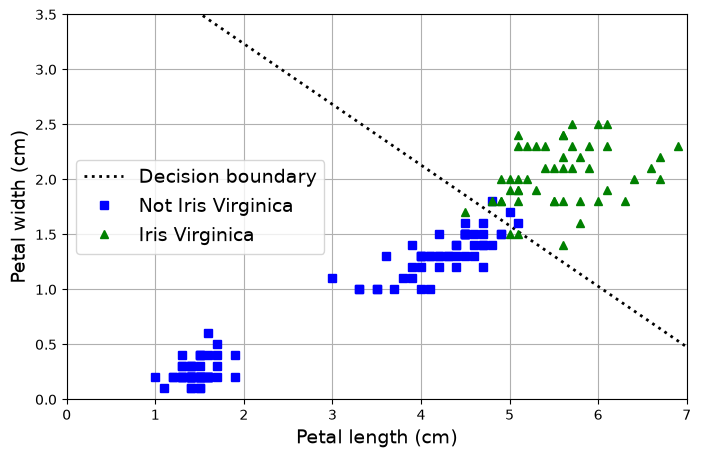

In [70]:
left_right = np.array([0, 7])
boundary = -(model.intercept_[0] + model.coef_[0][0]*left_right)/model.coef_[0][1]


plt.figure(figsize=(8, 5))
plt.plot(left_right, boundary, 'k:', linewidth=2, label='Decision boundary')
plt.plot(X[y==0, 0], X[y==0, 1], 'bs', label='Not Iris Virginica')
plt.plot(X[y==1, 0], X[y==1, 1], 'g^', label='Iris Virginica')

plt.xlabel('Petal length (cm)')
plt.ylabel('Petal width (cm)')
plt.legend(loc='center left')
plt.axis([0, 7, 0, 3.5])
plt.grid(True)
plt.show()

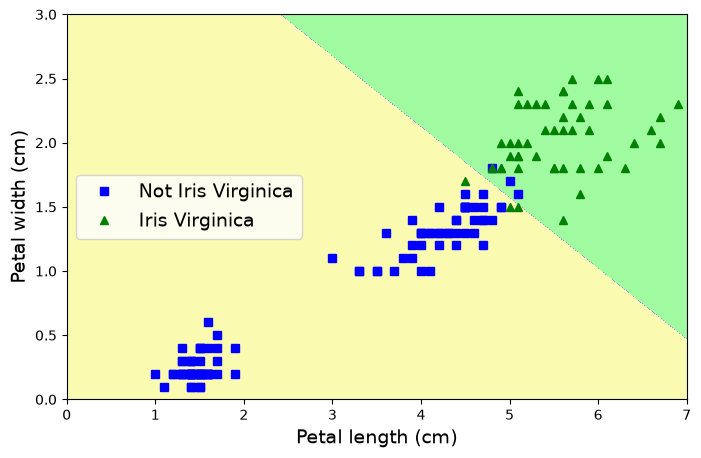

In [71]:
# petal length & width (cm)
X = iris.data[:, (2,3)]
y = (iris.target==2).astype(int)
 
model = LogisticRegression(C= 10**10)
model.fit(X, y)
 
x0, x1 = np.meshgrid(np.linspace(0, 7, 500)[:, np.newaxis],
                     np.linspace(0, 3, 500)[:, np.newaxis])
 
X_new = np.c_[x0.ravel(), x1.ravel()]
y_predict = model.predict(X_new)
zz = y_predict.reshape(x0.shape)
 
plt.figure(figsize=(8, 5))
plt.plot(X[y==0, 0], X[y==0, 1], 'bs', label='Not Iris Virginica')
plt.plot(X[y==1, 0], X[y==1, 1], 'g^', label='Iris Virginica')
 
from matplotlib.colors import ListedColormap
custom_map = ListedColormap(['#fafab0', '#9898ff', '#a0faa0'])
plt.contourf(x0, x1, zz, cmap=custom_map)
 
plt.xlabel('Petal length (cm)')
plt.ylabel('Petal width (cm)')
plt.legend(loc='center left')
plt.axis([0, 7, 0, 3])
#plt.grid()
plt.show()

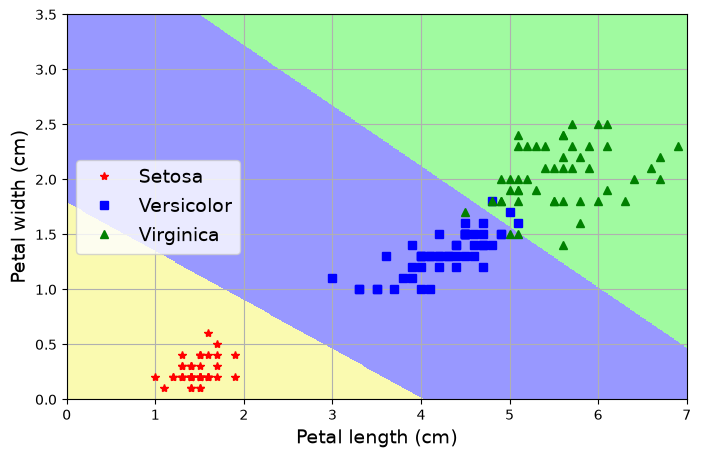

In [72]:
# petal length & width (cm)
X = iris.data[:, (2,3)]
y = iris.target
 
model = LogisticRegression(C=10**10)
model.fit(X, y)
 
x0, x1 = np.meshgrid(np.linspace(0, 8, 500)[:, np.newaxis],
                     np.linspace(0, 3.5, 500)[:, np.newaxis])
 
X_new = np.c_[x0.ravel(), x1.ravel()]
y_predict = model.predict(X_new)
zz = y_predict.reshape(x0.shape)
 
plt.figure(figsize=(8, 5))
plt.plot(X[y==0, 0], X[y==0, 1], 'r*', label='Setosa')
plt.plot(X[y==1, 0], X[y==1, 1], 'bs', label='Versicolor')
plt.plot(X[y==2, 0], X[y==2, 1], 'g^', label='Virginica')
 
from matplotlib.colors import ListedColormap
custom_map = ListedColormap(['#fafab0', '#9898ff', '#a0faa0'])
plt.contourf(x0, x1, zz, cmap=custom_map)
 
plt.xlabel('Petal length (cm)')
plt.ylabel('Petal width (cm)')
plt.legend(loc='center left')
plt.axis([0, 7, 0, 3.5])
plt.grid()
plt.show()